# SpaQFormer run: Human NSCLC (Lung13)


## 1. Imports and global Arial font


In [1]:
import gc
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

from SpaQFormer.evaluate import compute_label_metrics
from SpaQFormer.trainer import SpaQFormer

plt.rcParams.update({
    "font.family": "Arial",
    "font.sans-serif": ["Arial"],
    "axes.unicode_minus": False,
})

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 2. Dataset paths and best configuration


In [2]:
DATASET_NAME = "LC"
SC_FILE = r"C:\Code\Data\SpatialMap\NSCLC_9_1_reference.h5ad"
SRT_ITEMS = [{
    "name": "LC",
    "srt_file": r"C:\Code\Data\SpatialMap_Data\Data\Lung13_ST.h5ad",
}]
CONFIG_FILE = Path("Config") / "Config_LC.yaml"
OUTPUT_ROOT = Path(r"logs\spaqformer_lc_best")
GT_COL = "label_aligned"
INVALID_LABELS = {"unlabeled"}
INVALID_CASE_INSENSITIVE = True
NUM_PARTS = 10
CLUSTER_BATCH_SIZE = 1


OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
with CONFIG_FILE.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dataset: {DATASET_NAME}")
print(f"Device: {device}")
print(f"Targets: {[item['name'] for item in SRT_ITEMS]}")


Dataset: LC
Device: cuda
Targets: ['LC']


## 3. Model factory and evaluation filtering


In [3]:
def build_model(srt_file):
    return SpaQFormer(
        sc_file=SC_FILE,
        srt_file=srt_file,
        device=device,
        **config,
    )


def make_valid_mask(labels):
    labels = np.asarray(labels, dtype=str)
    if not INVALID_LABELS:
        return np.ones(len(labels), dtype=bool)
    if INVALID_CASE_INSENSITIVE:
        invalid = {str(label).lower() for label in INVALID_LABELS}
        return np.array([label.lower() not in invalid for label in labels])
    invalid = {str(label) for label in INVALID_LABELS}
    return np.array([label not in invalid for label in labels])

## 4. Stage 1: pretrain once on the scRNA-seq reference


In [4]:
first_item = SRT_ITEMS[0]
model = build_model(first_item["srt_file"])

print(f"sc_x: {model.sc_x.shape}")
print(f"first srt_x: {model.srt_x.shape}")
print(f"num_classes: {model.num_classes}")
print(f"hidden_dim: {model.hidden_dim}")

model.pretrain()
shared_model1 = model.model1

c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
c:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

sc_x: (49467, 952)
first srt_x: (82843, 952)
num_classes: 15
hidden_dim: 64


SpaQFormer pretrain:   0%|          | 0/50 [00:00<?, ?epoch/s]

## 5. Stages 2-4: pseudo-label, build prototypes, and annotate every target


In [5]:
run_results = {}
metric_records = []

for item_index, item in enumerate(SRT_ITEMS):
    item_name = item["name"]
    item_dir = OUTPUT_ROOT / item_name
    item_dir.mkdir(parents=True, exist_ok=True)
    current_model = model if item_index == 0 else build_model(item["srt_file"])
    if item_index > 0:
        current_model.model1 = shared_model1

    print(f"\n{'=' * 72}\nRunning {DATASET_NAME}/{item_name}\n{'=' * 72}")
    current_model.pseudo_label()

    current_model.build_prototypes()
    annotation = current_model.annotate(
        use_cluster=True,
        num_parts=NUM_PARTS,
        cluster_batch_size=CLUSTER_BATCH_SIZE,
        open_set=False,
    )
    prediction = np.asarray(annotation, dtype=str)

    # Store cell-aligned outputs in AnnData instead of an index-free NPZ file.
    target = ad.read_h5ad(item["srt_file"], backed="r")
    class_names = [
        str(current_model.inverse_dict[index])
        for index in range(current_model.num_classes)
    ]
    result_adata = ad.AnnData(obs=target.obs.copy())
    result_adata.obs["SpaQFormer_annotation"] = pd.Categorical(
        prediction,
        categories=class_names,
    )
    result_adata.obsm["X_SpaQFormer"] = np.asarray(
        current_model.srt_qformer_embeddings,
        dtype=np.float32,
    )

    output_h5ad = item_dir / f"spaqformer_{item_name.lower()}_best_results.h5ad"
    result_adata.write_h5ad(output_h5ad, compression="gzip")
    print(f"Saved AnnData results to: {output_h5ad}")

    labels = result_adata.obs[GT_COL].astype(str).to_numpy()
    prediction = result_adata.obs["SpaQFormer_annotation"].astype(str).to_numpy()
    valid_mask = make_valid_mask(labels)
    metrics = compute_label_metrics(labels[valid_mask], prediction[valid_mask])
    metrics["item"] = item_name
    metric_records.append(metrics)

    run_results[item_name] = {"result_h5ad": output_h5ad}

    target.file.close()
    del current_model, target, result_adata
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Running LC/LC


Computing METIS partitioning...
Done!


SpaQFormer cluster annotate:   0%|          | 0/100 [00:00<?, ?epoch/s]

Saved AnnData results to: logs\spaqformer_lc_best\LC\spaqformer_lc_best_results.h5ad


## 6. Evaluate


In [6]:
metrics_df = pd.DataFrame(metric_records).set_index("item")
print(metrics_df.T.to_string())


item                          LC
acc                     0.778305
precision_macro         0.470220
recall_macro            0.445203
f1_macro                0.403249
precision_weighted      0.735897
recall_weighted         0.778305
f1_weighted             0.735750
ari                     0.718876
nmi                     0.637656
kappa                   0.715614
mcc                     0.722868
n_eval              81143.000000


## 7. Ground truth and SpaQFormer spatial annotations


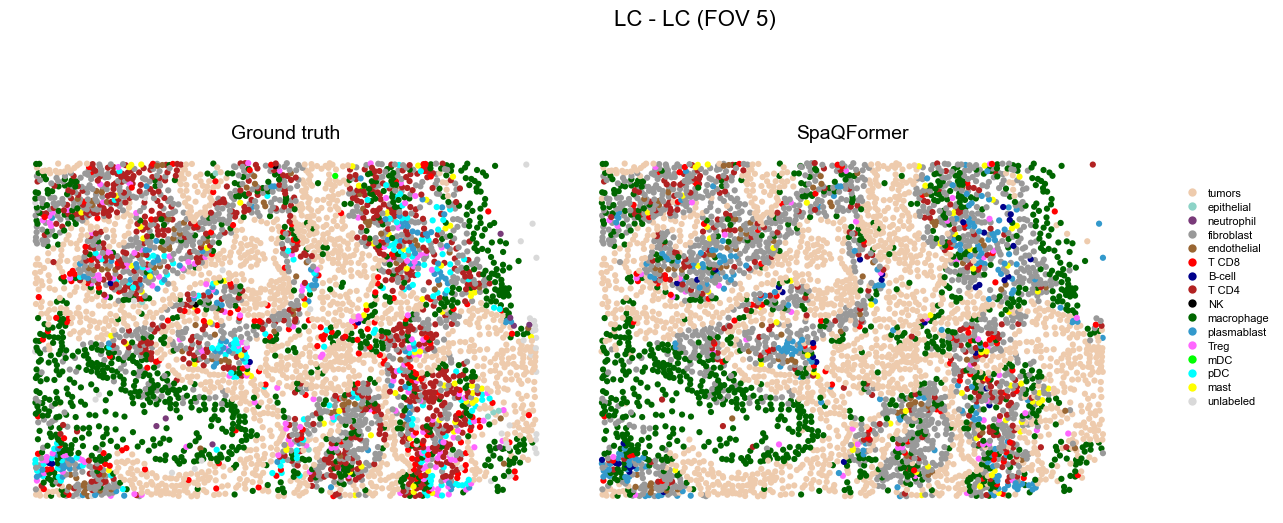

In [7]:
VISUALIZATION_FOV = "5"

# Fixed colors shared with the NSCLC visualization.
category_color_mapping = {
    "tumors": "#eecbad",
    "epithelial": "#8dd3c7",
    "neutrophil": "#793a79",
    "fibroblast": "#999999",
    "endothelial": "#996633",
    "T CD8": "#ff0000",
    "B-cell": "#00008b",
    "T CD4": "#b22222",
    "NK": "#000000",
    "macrophage": "#006600",
    "plasmablast": "#3399cc",
    "Treg": "#ff66ff",
    "mDC": "#00ff00",
    "pDC": "#00ffff",
    "mast": "#ffff00",
    "unlabeled": "#d9d9d9",
}


def stable_color_map(cell_types):
    """Return the fixed NSCLC color mapping for observed cell types."""
    observed_cell_types = {
        str(cell_type)
        for cell_type in cell_types
    }

    return {
        cell_type: category_color_mapping[cell_type]
        for cell_type in observed_cell_types
    }


for item_name, result in run_results.items():
    result_adata = ad.read_h5ad(result["result_h5ad"], backed="r")
    fov_mask = result_adata.obs["fov"].astype(str).eq(VISUALIZATION_FOV)
    plot_obs = result_adata.obs.loc[fov_mask]
    labels = plot_obs[GT_COL].astype(str).to_numpy()
    prediction = plot_obs["SpaQFormer_annotation"].astype(str).to_numpy()
    color_map = stable_color_map(np.concatenate([labels, prediction]))
    point_size = 20

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
    for ax, values, title in zip(
        axes,
        [labels, prediction],
        ["Ground truth", "SpaQFormer"],
    ):
        ax.scatter(
            plot_obs["x"],
            plot_obs["y"],
            c=[color_map[value] for value in values],
            s=point_size,
            linewidths=0,
            rasterized=True,
        )
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(title, fontsize=14)
        ax.axis("off")
    axes[0].invert_yaxis()
    fig.suptitle(
        f"{DATASET_NAME} - {item_name} (FOV {VISUALIZATION_FOV})",
        fontsize=16,
    )
    legend_cell_types = [
        cell_type
        for cell_type in category_color_mapping
        if cell_type in color_map
    ]
    legend_handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor=category_color_mapping[cell_type],
            markeredgecolor="none",
            markersize=6,
            label=cell_type,
        )
        for cell_type in legend_cell_types
    ]
    fig.legend(
        handles=legend_handles,
        loc="center left",
        bbox_to_anchor=(0.84, 0.5),
        frameon=False,
        fontsize=8,
        handletextpad=0.4,
        labelspacing=0.35,
    )
    fig.tight_layout(rect=(0.0, 0.0, 0.82, 0.95))
    plt.show()
    plt.close(fig)
    result_adata.file.close()


## 8. Cell-type gene attribution with IG, GS, and OC

Explain the first and only executed target after annotation, then save gene-level tables.


In [8]:
from SpaQFormer import SpaQFormerExplainer


# Only the first configured target is trained and explained.
explain_item = SRT_ITEMS[0]
explain_item_name = explain_item["name"]
explain_output_dir = OUTPUT_ROOT / explain_item_name / "explain"
explain_output_dir.mkdir(parents=True, exist_ok=True)

explainer = SpaQFormerExplainer(
    model,
    num_parts=50,
)

all_results = explainer.explain_all_cell_types(
    max_cells=50,
    methods=("ig", "gs", "oc"),
    top_k=20,
    ig_steps=16,
    gs_samples=8,
    perturbations_per_eval=16,
)


all_gene_score_tables = []
all_top_gene_tables = []

for cell_type, explanation in all_results.items():
    gene_scores = explanation["gene_scores"].copy()
    gene_scores.insert(0, "cell_type", cell_type)
    all_gene_score_tables.append(gene_scores)

    top_genes = explanation["top_genes"].copy()
    top_genes.insert(0, "cell_type", cell_type)
    all_top_gene_tables.append(top_genes)


all_gene_scores_df = pd.concat(
    all_gene_score_tables,
    ignore_index=True,
)
all_top_genes_df = pd.concat(
    all_top_gene_tables,
    ignore_index=True,
)

file_prefix = f"SpaQFormer_{explain_item_name}"
all_gene_scores_path = (
    explain_output_dir
    / f"{file_prefix}_all_cell_types_all_gene_scores.csv"
)
all_top_genes_path = (
    explain_output_dir
    / f"{file_prefix}_all_cell_types_top20_genes.csv"
)

all_gene_scores_df.to_csv(
    all_gene_scores_path,
    index=False,
    encoding="utf-8-sig",
)
all_top_genes_df.to_csv(
    all_top_genes_path,
    index=False,
    encoding="utf-8-sig",
)


print(f"All gene scores: {all_gene_scores_path}")
print(f"Top 20 genes: {all_top_genes_path}")

display(all_top_genes_df.groupby("cell_type").head(10))

Computing METIS partitioning...
Done!


Skip mDC: No cells were predicted as mDC.
Skip neutrophil: No cells were predicted as neutrophil.
Skip pDC: No cells were predicted as pDC.
All gene scores: logs\spaqformer_lc_best\LC\explain\SpaQFormer_LC_all_cell_types_all_gene_scores.csv
Top 20 genes: logs\spaqformer_lc_best\LC\explain\SpaQFormer_LC_all_cell_types_top20_genes.csv


,cell_type,gene,ig_score,ig_rank,gs_score,gs_rank,oc_score,oc_rank,borda_score,final_rank
0,B-cell,IGHA1,0.618682,1,0.606064,1,0.724837,1,2856.0,1
1,B-cell,JCHAIN,0.414820,2,0.408131,2,0.259404,2,2853.0,2
2,B-cell,IGHM,0.238377,3,0.242654,3,0.247416,3,2850.0,3
3,B-cell,IGKC,0.116335,4,0.117356,4,0.044126,6,2845.0,4
4,B-cell,MALAT1,0.096468,5,0.096761,5,0.054858,5,2844.0,5
...,...,...,...,...,...,...,...,...,...,...
225,tumors,SQSTM1,0.247766,3,0.216106,3,0.054551,19,2834.0,6
226,tumors,HLA-A,0.095862,11,0.091440,11,0.107630,5,2832.0,7
227,tumors,HLA-B,0.088450,12,0.093063,10,0.085123,8,2829.0,8
228,tumors,NDRG1,0.122547,8,0.110251,9,0.061518,14,2828.0,9
